# Assignment 3: K-Nearest Neighbors on diabetes.csv

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, classification_report

In [2]:
df = pd.read_csv("diabetes.csv")
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


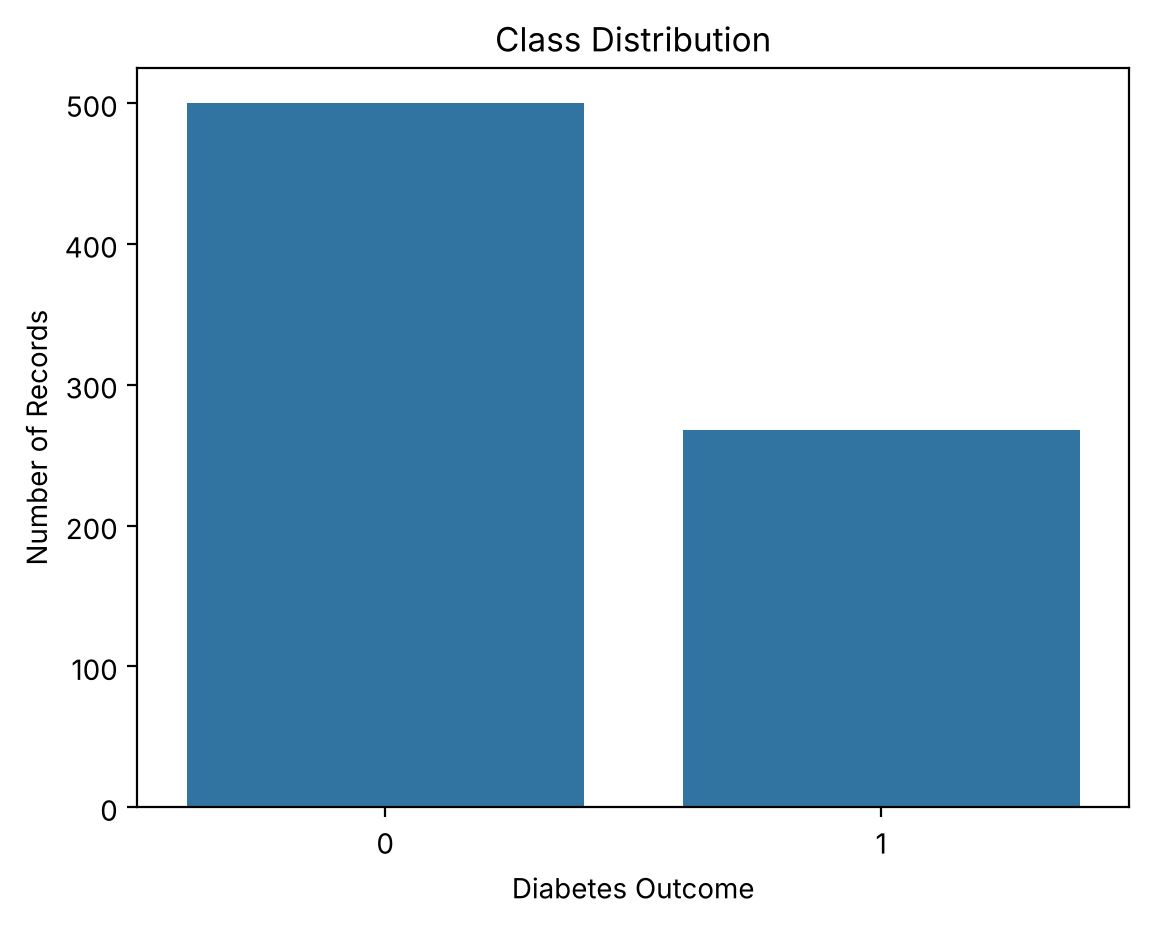

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


In [3]:
sns.countplot(x=df["Outcome"])
plt.xlabel("Diabetes Outcome"); plt.ylabel("Number of Records"); plt.title("Class Distribution")
plt.show()
print(df.isnull().sum())

In [4]:
# Zeros in these columns are impossible values => treat as missing and fill with the median
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[cols] == 0).sum())
df[cols] = df[cols].replace(0, np.nan)
df[cols] = df[cols].fillna(df[cols].median())
print("Zeros left:", (df[cols] == 0).sum().sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Zeros left: 0


In [5]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training data:", X_train.shape, "| Testing data:", X_test.shape)

Training data: (614, 8) | Testing data: (154, 8)


In [6]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

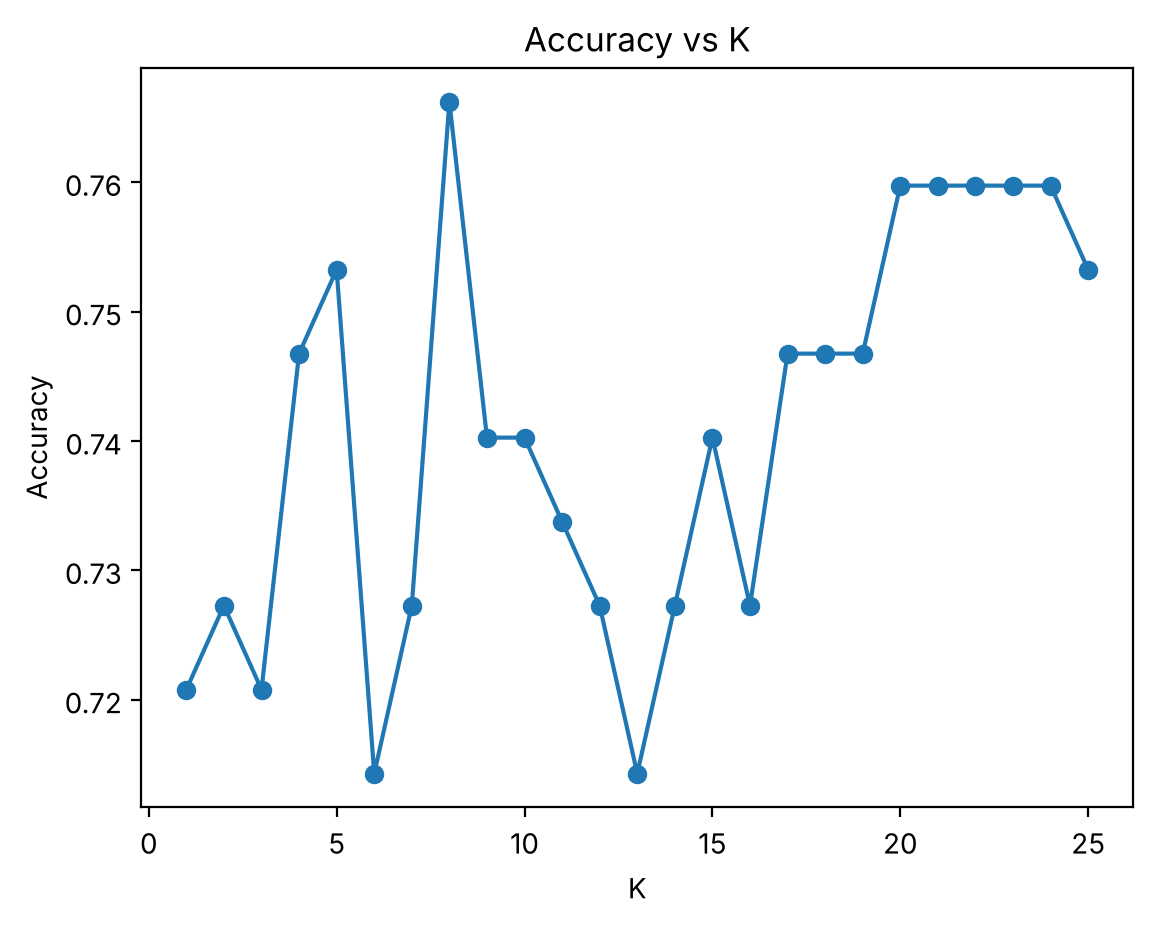

Accuracy with K=5: 0.7532467532467533


In [7]:
# Choose K: accuracy on test data for different values of K
ks = range(1, 26)
accs = [accuracy_score(y_test, KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train).predict(X_test)) for k in ks]
plt.plot(ks, accs, marker='o'); plt.xlabel("K"); plt.ylabel("Accuracy"); plt.title("Accuracy vs K"); plt.show()
print("Accuracy with K=5:", accs[4])

In [8]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(y_pred)

[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 1 0 0
 0 1 0 1 0 0 0 0 0 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 0 0 1 0 0 0 1
 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 0 1 1 1
 1 1 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0 0 0 0 1 1 0 0 0 0 1 0 1 0 0 0 0 1 0
 0 0 0 0 1 0]


Confusion Matrix:
 [[83 17]
 [21 33]]


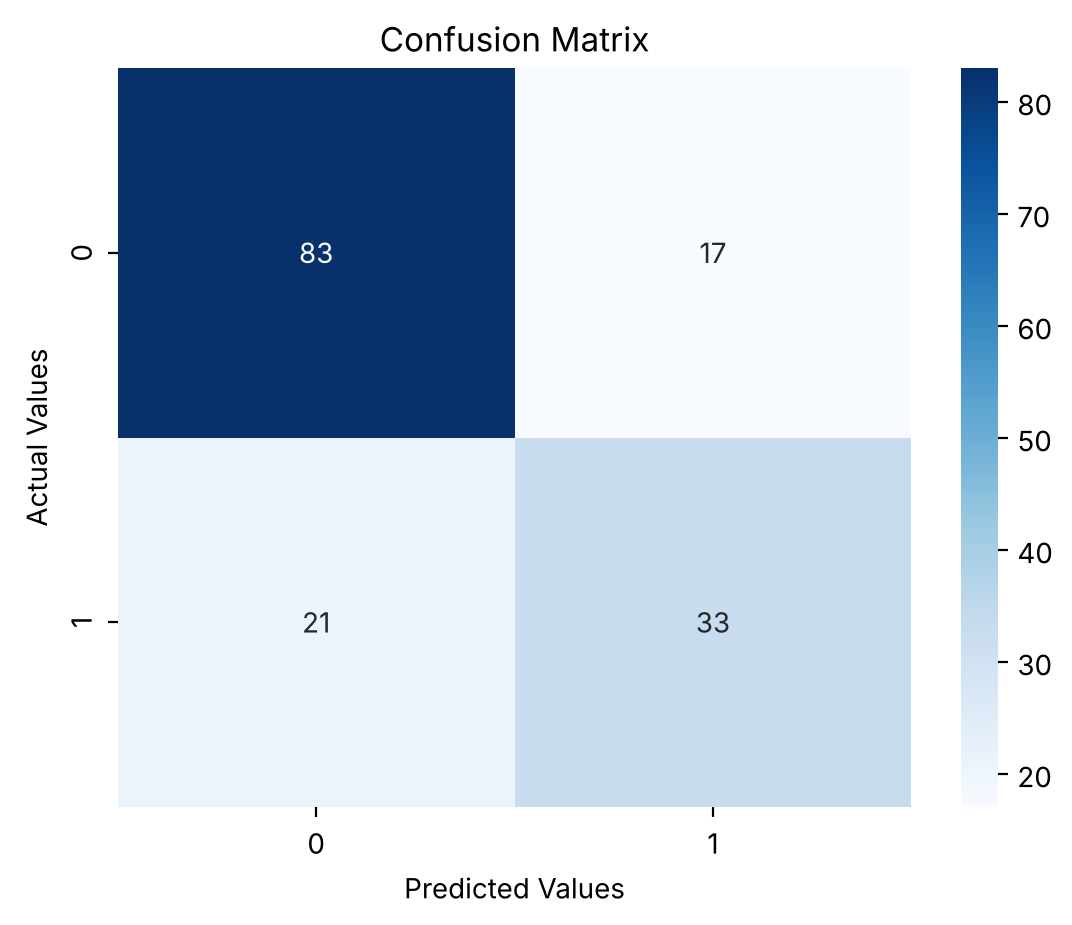

In [9]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Values"); plt.ylabel("Actual Values"); plt.title("Confusion Matrix")
plt.show()

In [10]:
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
print("Accuracy  :", round(accuracy*100, 2), "%")
print("Error Rate:", round(error_rate*100, 2), "%")
print("Precision :", round(precision*100, 2), "%")
print("Recall    :", round(recall*100, 2), "%")
print()
print(classification_report(y_test, y_pred))

Accuracy  : 75.32 %
Error Rate: 24.68 %
Precision : 66.0 %
Recall    : 61.11 %

              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [11]:
pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred}).head(10)

,Actual,Predicted
0,0,1
1,0,0
2,0,0
3,1,1
4,0,0
5,0,0
6,1,0
7,1,1
8,0,0
9,0,1
